# Task 4 – Teil 5: Lastflussumkehr

**Ausgangspunkt:** das Netz am Ende von Teil 4. Es umfasst:
- CIGRE-MV ohne DER (Baseline des Arbeitsauftrags) mit dem ausgelegten Ortsnetz an Bus 12,
- rONT-Regelung und Backup-Plan aus Teil 3b,
- Windpark (30 MW) an Bus 1 und PV-Freiflächenanlage (10 MWp) an Bus 12 aus Teil 4a,
- PV-Haushalte im Ortsnetz, Variante „heute“ (8,3 % der Haushaltslast mit Profil P25, 6,7 % mit S25) aus Teil 4a.

Voraussetzung: `Task4-4a_Erzeugung_Anschluss.ipynb` wurde ausgeführt (Simulation `w4_kombi_W1_P12`).

### Anforderungen aus dem Arbeitsauftrag (Abschnitt 5)

> *Betrachten Sie im folgenden immer die möglichen Schalterstellungen der Schalter S1–S3. Werten Sie Wirkleistungsflüsse an geeigneten Leitungen, Netzkuppelstellen und Transformatoren aus. Erklären Sie anhand der verwendeten pandapower-Ergebnisfelder deren Vorzeichen und leiten Sie daraus ab, wann ein Leistungsfluss seine Richtung wechselt. Untersuchen Sie, welche Erzeugungs- und Lastbedingungen die Umkehr auslösen, wie stark und wie häufig sie auftritt und welche Folgen sich für Spannungen, Auslastungen und die Regelung des Ortsnetztransformators ergeben. Zeitreihen, Dauerlinien oder eine räumliche Darstellung der Flüsse können den Vergleich unterstützen.*

| Anforderung | wo |
|---|---|
| Wirkleistungsflüsse an Leitungen, Netzkuppelstelle (110 kV) und Trafos | Abschnitt 3 und 4 |
| Vorzeichen der pandapower-Ergebnisfelder, Kriterium für den Richtungswechsel | Abschnitt 2 |
| alle Schalterstellungen S1–S3 | Abschnitt 4 |
| auslösende Erzeugungs- und Lastbedingungen | Abschnitt 3 (Normalzustand) |
| Stärke und Häufigkeit der Umkehr | Abschnitt 3 und 4 (Stunden), Dauerlinien folgen |
| Folgen für Spannungen, Auslastungen und rONT-Regelung | folgt |
| Zeitreihen, Dauerlinien, räumliche Darstellung | teilweise (Abschnitt 3), Rest folgt |

### Aufbau

1. Netz am Ende von Teil 4 erstellen
2. Vorzeichen der Ergebnisfelder
3. Normalzustand: Wo kehrt sich der Leistungsfluss um, und welche Muster gibt es?
4. Alle Schalterstellungen: Änderung der Leistungsflüsse gegenüber dem Normalzustand
5. Zwischenstand und offene Punkte

## Importe

In [1]:
import copy

import numpy as np
import pandas as pd
import pandapower as pp
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import lvnetz
import regelung as rg
import bewertung as bw
import plots
import netplan
from elements import Diagram
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

sim.ONLY_RUN_IF_CHANGED = True
PLAN_MARKER = [("orange", 0.95, "Planungsband 0,95 pu", "--"), ("orange", 1.05, "Planungsband 1,05 pu", "--")]
SCHWELLE = 0.001                                         # |P| unter 1 kW gilt als „kein Fluss“

kombi = sim.loadSimulation("w4_kombi_W1_P12")           # Teil 4a: gewählte Kombination, Ortsnetz mit Standardprofilen

## 1 Netz am Ende von Teil 4

Kopie der gewählten Kombination aus Teil 4a; zusätzlich werden die Haushaltslasten im Ortsnetz wie in Teil 4a, Variante „heute“, aufgeteilt (`lvnetz.prosumer`).

**Regelung:** Für alle Rechnungen in diesem Notebook laufen nur die drei rONT-Regler. Der Backup-Plan (`SchaltPlan`) öffnet beim Start alle Trennschalter und würde damit die vorgegebenen Schalterstellungen in Abschnitt 4 überschreiben. Im Normalzustand löst er ohnehin nie aus (Teil 3b, Teil 4a).

In [2]:
PV_HAUSHALTE = (0.083, 0.067)                            # Variante „heute“ aus Teil 4a: Anteil P25, Anteil S25
basis = kombi.copy("w4_t5_basis", overwrite=True)
aufteilung = lvnetz.prosumer(basis, *PV_HAUSHALTE)
basis.save(results=False)

def lv_regler(net):
    return [r for r in rg.standard_regler(net) if isinstance(r, rg.TapRegler)]

print("Erzeuger:")
display(basis.net.sgen[["name", "p_mw"]].assign(Bus=basis.net.bus.loc[basis.net.sgen.bus, "name"].to_numpy()))
print("Lasten je Profil:")
basis.net.load.groupby("profile").agg(Anzahl=("name", "size"), Hoechstleistung_MW=("p_mw", "sum"))

Erzeuger:


,name,p_mw,Bus
0,Windpark,30.0,Bus 1
1,PV-Freifläche,10.0,Bus 12


Lasten je Profil:


,Anzahl,Hoechstleistung_MW
profile,,
GEWERBE,17,11.472800
HAUSHALT,16,33.898380
HAUSHALT_PV,6,0.031855
HAUSHALT_PV_SPEICHER,6,0.025715


In [3]:
normal = sz.zeitreihe_alle(basis, prefix="w4_t5", keys=["000"], controllers=lv_regler(basis.net))["000"]
werte, _ = bw.kennwerte({"Teil 4a: Kombination": kombi, "Teil 4a: PV-Haushalte heute": sim.loadSimulation("w4_ortsnetz_pv_heute"),
                         "Netz am Ende von Teil 4": normal})
plots.table(werte[["U max gesamt [pu]", "U min gesamt [pu]", "Leitung max MS [%]", "Leitung max NS [%]", "Trafo max HS/MS [%]",
                   "Ortsnetztrafo max [%]", "Stunden Rückspeisung 110 kV", "max. Rückspeisung 110 kV [MW]", "Verluste [MWh]"]].astype(float),
            decimals=3)

Simulation 'w4_t5_000': 2016 Lastflüsse in 73 s, nicht konvergiert: 0


,U max gesamt [pu],U min gesamt [pu],Leitung max MS [%],Leitung max NS [%],Trafo max HS/MS [%],Ortsnetztrafo max [%],Stunden Rückspeisung 110 kV,max. Rückspeisung 110 kV [MW],Verluste [MWh]
Teil 4a: Kombination,1.027,0.950,78.491,71.073,88.512,66.838,263.000,16.100,151.602
Teil 4a: PV-Haushalte heute,1.026,0.949,78.638,69.969,82.694,65.830,0.000,0.000,161.898
Netz am Ende von Teil 4,1.026,0.950,78.491,69.969,88.512,65.830,263.000,16.089,150.712


**Das neue Netz** enthält alle drei Szenarien aus Teil 4 gleichzeitig: Windpark an Bus 1, PV-Anlage an Bus 12 und 12 zusätzliche Haushaltslasten mit den Profilen P25 und S25 im Wohngebiet.

- Im Vergleich mit der Kombination aus Teil 4a ändern die PV-Haushalte im MS-Netz fast nichts: Rückspeisestunden, höchste Rückspeisung und Trafoauslastung bleiben praktisch gleich.
- Im Ortsnetz sinken die höchste NS-Leitungsauslastung (71,1 → 70,0 %) und die Auslastung der Ortsnetztrafos (66,8 → 65,8 %) leicht, weil die P25/S25-Haushalte weniger aus dem Netz beziehen.
- Alle Spannungen bleiben im Planungsband (0,950 bis 1,026 pu).

## 2 Vorzeichen der Ergebnisfelder

pandapower verwendet für Lasten das Verbraucherzählpfeilsystem und für Erzeuger das Erzeugerzählpfeilsystem. Für Leitungen und Trafos gibt das Vorzeichen die Richtung bezogen auf die Anschlussseite an:

| Element | Ergebnisfeld (gespeichert als) | positiv | negativ |
|---|---|---|---|
| Leitung | `res_line.p_from_mw` (`results.line_p_mw`) | Wirkleistung fließt von `from_bus` in die Leitung, also von `from_bus` zu `to_bus` | Fluss von `to_bus` zu `from_bus` |
| Trafo | `res_trafo.p_hv_mw` (`results.trafo_p_mw`) | Fluss von der Oberspannungs- zur Unterspannungsseite (Bezug aus dem überlagerten Netz) | Fluss von US nach OS (**Rückspeisung**) |
| Netzkuppelstelle (110 kV) | `res_ext_grid.p_mw` (`results.ext_grid_p_mw`) | Bezug aus dem 110-kV-Netz | Rückspeisung ins 110-kV-Netz |
| Last | `res_load.p_mw` | Verbrauch | – |
| Erzeuger | `res_sgen.p_mw` | Einspeisung | – |

**Richtungswechsel:** Ein Leistungsfluss wechselt seine Richtung, wenn das Vorzeichen des Ergebnisfelds wechselt. Als Hauptrichtung eines Elements gilt das Vorzeichen, das in den meisten Stunden auftritt. Jede Stunde mit dem anderen Vorzeichen zählt als Umkehr. Werte mit |P| < 1 kW gelten als „kein Fluss“, damit Rechenrauschen an offenen Leitungen nicht als Umkehr zählt.

Die Leitungsnamen geben die Richtung von `from_bus` zu `to_bus` an: Bei „Line 1-2“ heißt positiv also Fluss von Bus 1 zu Bus 2. Beispiel für eine Stunde mit Rückspeisung:

In [4]:
r = normal.results
h_rueck = r.ext_grid_p_mw.squeeze().idxmin()
beispiel = pd.Series({
    "Windpark (sgen) [MW]": r.sgen_p_mw.at[h_rueck, "Windpark"],
    "PV-Freifläche (sgen) [MW]": r.sgen_p_mw.at[h_rueck, "PV-Freifläche"],
    "Summe Lasten [MW]": r.load_p_mw.loc[h_rueck].sum(),
    "Trafo 0-1, p_hv_mw [MW]": r.trafo_p_mw.at[h_rueck, "Trafo 0-1"],
    "Trafo 0-12, p_hv_mw [MW]": r.trafo_p_mw.at[h_rueck, "Trafo 0-12"],
    "Line 1-2, p_from_mw [MW]": r.line_p_mw.at[h_rueck, "Line 1-2"],
    "110-kV-Netz, ext_grid p_mw [MW]": r.ext_grid_p_mw.squeeze()[h_rueck],
}, name=f"{h_rueck:%d.%m. %H:%M}")
beispiel.to_frame()

,19.12. 02:00
Windpark (sgen) [MW],29.487000
PV-Freifläche (sgen) [MW],0.000000
Summe Lasten [MW],13.341705
"Trafo 0-1, p_hv_mw [MW]",-22.318591
"Trafo 0-12, p_hv_mw [MW]",6.229127
"Line 1-2, p_from_mw [MW]",1.298714
"110-kV-Netz, ext_grid p_mw [MW]",-16.089463


**Beispiel (19.12., 2 Uhr, stärkste Rückspeisung):** Der Windpark speist 29,5 MW ein, alle Lasten zusammen brauchen 13,3 MW.

- `Trafo 0-1` hat `p_hv_mw = −22,3 MW`: Leistung fließt von der 20-kV- zur 110-kV-Seite, der Trafo speist zurück.
- `Trafo 0-12` hat `+6,2 MW`: Abgang 2 bezieht weiter aus dem 110-kV-Netz.
- Die Netzkuppelstelle zeigt `−16,1 MW`: Rückspeisung ins 110-kV-Netz, die Differenz der beiden Trafos abzüglich der Verluste.
- `Line 1-2` bleibt positiv (+1,3 MW): Auch bei Rückspeisung fließt auf der Leitung weiter Leistung von Bus 1 in den Abgang, nur jetzt aus dem Windpark statt aus dem Trafo.

## 3 Normalzustand: Wo kehrt sich der Leistungsfluss um?

Für jede Leitung, jeden Trafo und die Netzkuppelstelle: Hauptrichtung, Stunden in Gegenrichtung und größter Fluss in Gegenrichtung (12 Wochen, 2016 Stunden).

In [5]:
def fluesse(s):
    """Wirkleistungsflüsse aller Leitungen, Trafos und der Netzkuppelstelle [MW] (Spalten = Elemente)."""
    rr = s.results
    return pd.concat([rr.line_p_mw, rr.trafo_p_mw, rr.ext_grid_p_mw.rename(columns={"ext_grid_p_mw": "110-kV-Netz"})], axis=1)

def richtungen(P):
    """Je Element: Stunden mit positivem / negativem Fluss, Hauptrichtung, Stunden in Gegenrichtung."""
    pos, neg = (P > SCHWELLE).sum(), (P < -SCHWELLE).sum()
    haupt = np.where(pos >= neg, 1, -1)
    gegen = np.where(haupt > 0, neg, pos)
    max_gegen = [(-P[c]).clip(lower=0).max() if h > 0 else P[c].clip(lower=0).max() for c, h in zip(P.columns, haupt)]
    return pd.DataFrame({"Stunden P > 0": pos, "Stunden P < 0": neg, "Hauptrichtung": np.where(haupt > 0, "+", "−"),
                         "Stunden Gegenrichtung": gegen, "max. Fluss Gegenrichtung [MW]": max_gegen}, index=P.columns)

P0 = fluesse(normal)
mv = [c for c in P0 if c.startswith(("Line", "Trafo")) or c == "110-kV-Netz"]
ortsnetz = [c for c in P0 if c.startswith("LV")]
rt = richtungen(P0)
print("MS-Netz, Trafos und Netzkuppelstelle:")
display(rt.loc[mv])
print(f"Ortsnetz: {len(ortsnetz)} Leitungen und Trafos, davon mit Gegenrichtung:",
      list(rt.loc[ortsnetz].query("`Stunden Gegenrichtung` > 0").index) or "keine")

MS-Netz, Trafos und Netzkuppelstelle:


,Stunden P > 0,Stunden P < 0,Hauptrichtung,Stunden Gegenrichtung,max. Fluss Gegenrichtung [MW]
Line 1-2,2016,0,+,0,0.000000
Line 2-3,2016,0,+,0,0.000000
Line 3-4,2016,0,+,0,0.000000
Line 4-5,2016,0,+,0,0.000000
Line 5-6,2016,0,+,0,0.000000
Line 7-8,0,2016,−,0,0.000000
Line 8-9,2016,0,+,0,0.000000
Line 9-10,2016,0,+,0,0.000000
Line 10-11,2016,0,+,0,0.000000
Line 3-8,2016,0,+,0,0.000000


Ortsnetz: 40 Leitungen und Trafos, davon mit Gegenrichtung: keine


**Muster:** Wann tritt die Umkehr an Trafo 0-1 und an der Netzkuppelstelle auf? Verteilung der Stunden mit Rückspeisung nach Uhrzeit und Monat:

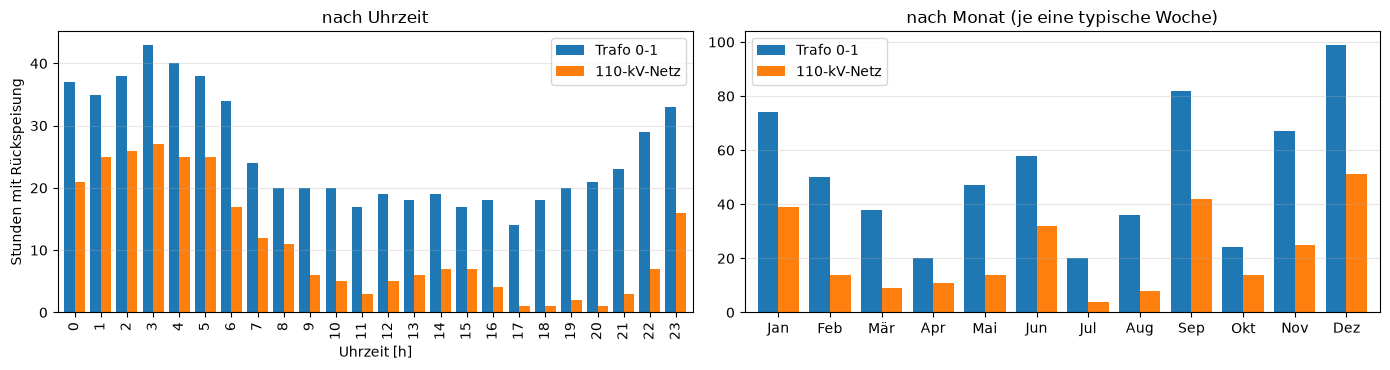

In [6]:
info = r.info
rueck = pd.DataFrame({"Trafo 0-1": P0["Trafo 0-1"] < -SCHWELLE, "110-kV-Netz": P0["110-kV-Netz"] < -SCHWELLE})
monate = list(dict.fromkeys(info["month"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
rueck.groupby(rueck.index.hour).sum().plot.bar(ax=axes[0], width=0.8)
axes[0].set_xlabel("Uhrzeit [h]")
axes[0].set_ylabel("Stunden mit Rückspeisung")
axes[0].set_title("nach Uhrzeit")
rueck.groupby(info["month"].to_numpy()).sum().reindex(monate).plot.bar(ax=axes[1], width=0.8)
axes[1].set_xticklabels([Month[m].label[:3] for m in monate], rotation=0)
axes[1].set_xlabel("")
axes[1].set_title("nach Monat (je eine typische Woche)")
for ax in axes:
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

**Auslösende Bedingungen:** Trafo 0-1 kehrt sich um, wenn der Windpark mehr einspeist, als Abgang 1 (Bus 1 bis Bus 11) verbraucht. Die Netzkuppelstelle kehrt sich um, wenn Windpark und PV-Anlage zusammen mehr einspeisen, als das ganze Netz verbraucht. Die gestrichelte Linie markiert Erzeugung = Last; jeder Punkt ist eine Stunde.

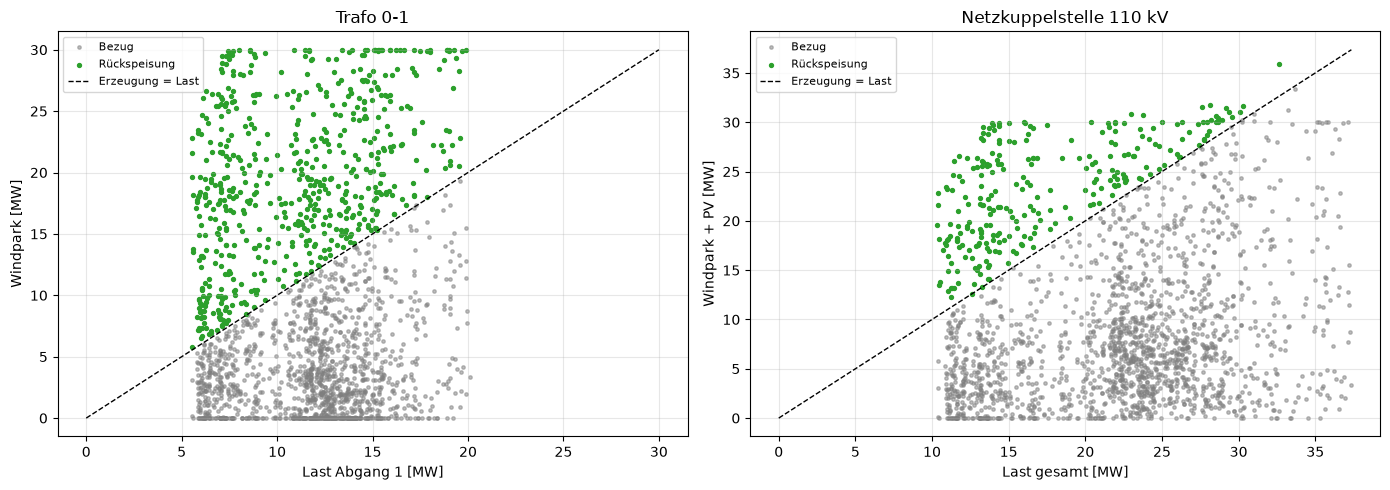

,Stunden,Wind im Mittel [MW],PV im Mittel [MW],Last gesamt im Mittel [MW],Anteil nachts (22–6 Uhr),Anteil Wochenende
Rückspeisung Trafo 0-1,615.00,19.41,0.71,20.56,0.48,0.31
Rückspeisung 110 kV,263.00,22.74,0.59,17.32,0.65,0.36
alle Stunden,2016.00,8.62,1.40,22.00,0.33,0.29


In [7]:
bus_der_last = basis.net.load.set_index("name")["bus"].map(basis.net.bus["name"])
abgang1 = [l for l, b in bus_der_last.items() if b in [f"Bus {i}" for i in range(1, 12)]]
last_abgang1 = r.load_p_mw[abgang1].sum(axis=1)
last_gesamt = r.load_p_mw.sum(axis=1)
wind, pv = r.sgen_p_mw["Windpark"], r.sgen_p_mw["PV-Freifläche"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x, y, umkehr, titel, xl, yl in (
        (axes[0], last_abgang1, wind, rueck["Trafo 0-1"], "Trafo 0-1", "Last Abgang 1 [MW]", "Windpark [MW]"),
        (axes[1], last_gesamt, wind + pv, rueck["110-kV-Netz"], "Netzkuppelstelle 110 kV", "Last gesamt [MW]", "Windpark + PV [MW]")):
    ax.scatter(x[~umkehr], y[~umkehr], s=6, color="tab:gray", alpha=0.5, label="Bezug")
    ax.scatter(x[umkehr], y[umkehr], s=8, color="tab:green", label="Rückspeisung")
    m = max(x.max(), y.max())
    ax.plot([0, m], [0, m], "k--", lw=1, label="Erzeugung = Last")
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
    ax.set_title(titel)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

bedingungen = pd.DataFrame({
    titel: {"Stunden": int(u.sum()), "Wind im Mittel [MW]": wind[u].mean(), "PV im Mittel [MW]": pv[u].mean(),
            "Last gesamt im Mittel [MW]": last_gesamt[u].mean(), "Anteil nachts (22–6 Uhr)": (u & ((u.index.hour >= 22) | (u.index.hour < 6))).sum() / max(u.sum(), 1),
            "Anteil Wochenende": (u & (u.index.dayofweek >= 5)).sum() / max(u.sum(), 1)}
    for titel, u in (("Rückspeisung Trafo 0-1", rueck["Trafo 0-1"]), ("Rückspeisung 110 kV", rueck["110-kV-Netz"]),
                     ("alle Stunden", pd.Series(True, index=rueck.index)))})
plots.table(bedingungen.T, decimals=2)

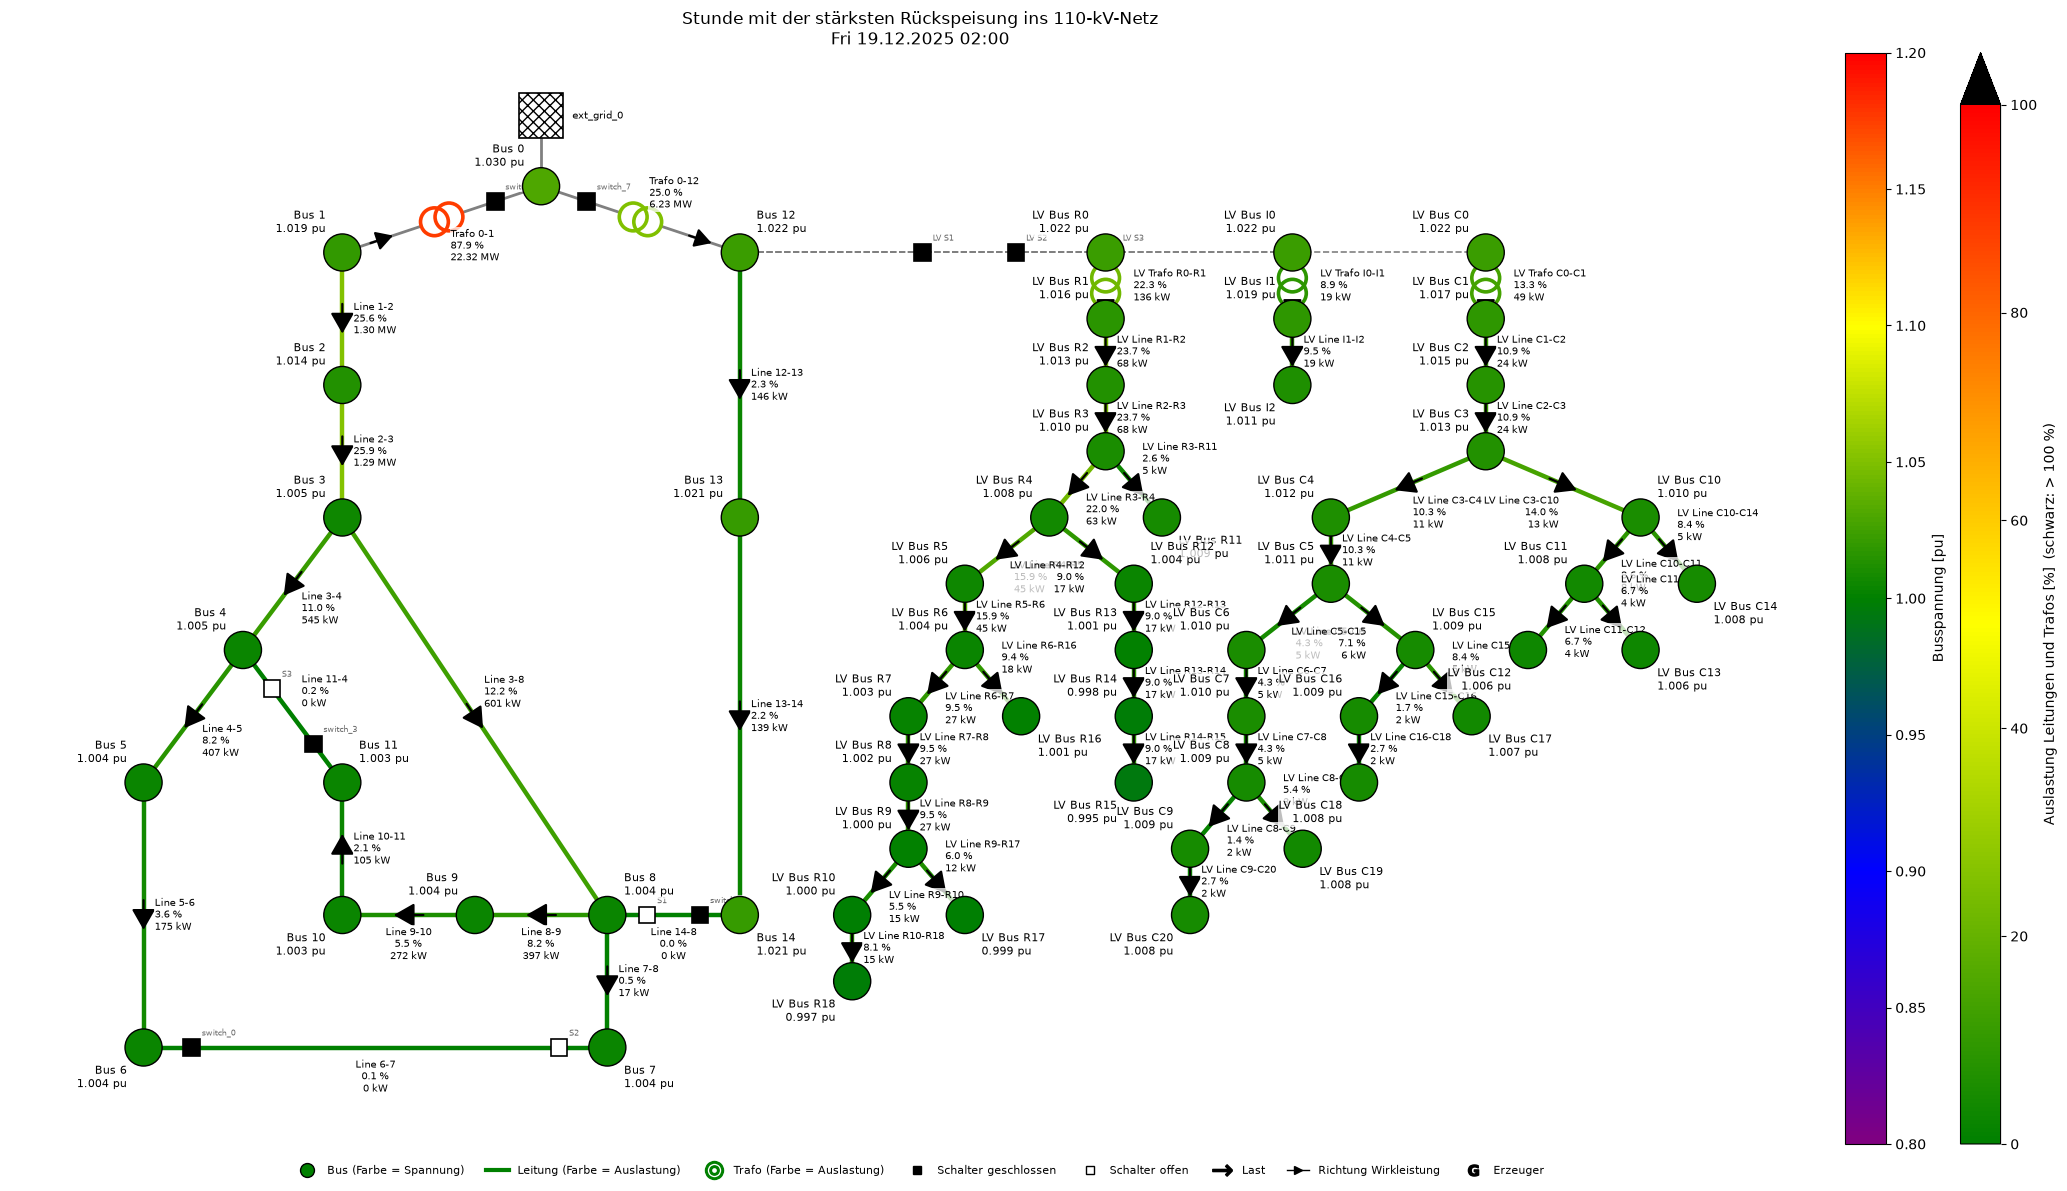

In [8]:
normal.createDiagram(Diagram.NETWORK, time=[h_rueck], elements=False, title="Stunde mit der stärksten Rückspeisung ins 110-kV-Netz")

**Ergebnis Normalzustand:**

- **Wo:** Der Leistungsfluss kehrt sich nur an zwei Stellen um: an **Trafo 0-1** (615 von 2016 Stunden, bis 22,5 MW) und an der **Netzkuppelstelle zum 110-kV-Netz** (263 Stunden, bis 16,1 MW). Alle MS-Leitungen, Trafo 0-12 und das ganze Ortsnetz behalten immer ihre Richtung.
- **Warum nur dort:** Windpark und PV-Anlage speisen direkt an den Trafo-Sammelschienen ein. Ein Überschuss fließt sofort über den Trafo ab und läuft nie durch die Abgänge. Die PV-Haushalte (P25, S25) sind reine Bezugsprofile ohne Einspeisung und verringern nur den Bezug.
- **Auslöser:** Die Umkehr wird praktisch nur durch **Wind** ausgelöst. In den Stunden mit Rückspeisung speist der Windpark im Mittel 19 MW (Trafo 0-1) bzw. 23 MW (110 kV) ein, sonst im Mittel knapp 9 MW. Die PV-Anlage liegt in diesen Stunden sogar unter ihrem Mittelwert (0,6 bis 0,7 MW gegenüber 1,4 MW). Die Regel lässt sich direkt im Streudiagramm ablesen:
  - Trafo 0-1 speist zurück, sobald der Windpark mehr einspeist, als Abgang 1 verbraucht.
  - Das 110-kV-Netz bekommt Leistung zurück, sobald Wind und PV zusammen mehr liefern, als das ganze Netz verbraucht.
- **Wann:** Rückspeisung ins 110-kV-Netz tritt vor allem **nachts** auf (65 % der Stunden zwischen 22 und 6 Uhr), wenn die Last niedrig ist, und häufiger am Wochenende. Nach Monaten ist sie in den windreichen Wochen am häufigsten (Dezember, September, Januar) und im Juli und April am seltensten. Weil je Monat nur eine typische Woche gerechnet wird, spiegelt das eher das Wetter dieser einzelnen Woche als eine Jahreszeit; tendenziell liegt der Schwerpunkt im Winterhalbjahr. Abends kommt sie kaum vor, weil dann die Haushaltslast am höchsten ist.
- **PV allein reicht nie:** 10 MWp an Bus 12 liegen mittags immer unter der Last von Abgang 2 und des Netzes, deshalb kehrt sich Trafo 0-12 nie um.

## 4 Alle Schalterstellungen: Änderung der Leistungsflüsse

Die acht Schaltzustände (S1, S2, S3 jeweils offen oder geschlossen) werden als feste Betriebszustände über 12 Wochen gerechnet, wie in Teil 1 und Teil 3b.

In [9]:
alle = sz.zeitreihe_alle(basis, prefix="w4_t5", controllers=lv_regler(basis.net))
P = {k: fluesse(s) for k, s in alle.items()}
spalten = {k: sz.label(k, kurz=True) for k in alle}
elemente = [c for c in P["000"] if c.startswith(("Line", "Trafo", "LV Trafo")) or c == "110-kV-Netz"]
print(len(alle), "Schaltzustände;", len(elemente), "Elemente (MS-Leitungen, alle Trafos, Netzkuppelstelle)")

Simulation 'w4_t5_000': unverändert seit dem Lauf vom 2026-11-07T16:41:33 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t5_001': 2016 Lastflüsse in 66 s, nicht konvergiert: 0
Simulation 'w4_t5_010': 2016 Lastflüsse in 67 s, nicht konvergiert: 0
Simulation 'w4_t5_011': 2016 Lastflüsse in 68 s, nicht konvergiert: 0
Simulation 'w4_t5_100': 2016 Lastflüsse in 68 s, nicht konvergiert: 0
Simulation 'w4_t5_101': 2016 Lastflüsse in 68 s, nicht konvergiert: 0
Simulation 'w4_t5_110': 2016 Lastflüsse in 68 s, nicht konvergiert: 0
Simulation 'w4_t5_111': 2016 Lastflüsse in 71 s, nicht konvergiert: 0
8 Schaltzustände; 21 Elemente (MS-Leitungen, alle Trafos, Netzkuppelstelle)


**Mittlere Änderung des Wirkleistungsflusses gegenüber dem Normalzustand (alle Schalter offen)** in MW, gemittelt über alle 2016 Stunden. Das Vorzeichen bezieht sich auf die Richtung des Ergebnisfelds (Abschnitt 2): Ein positiver Wert heißt, der Fluss in Richtung `from_bus` → `to_bus` bzw. OS → US nimmt zu. Die Leitungen mit S1–S3 (Line 14-8, 6-7, 11-4) führen im Normalzustand keine Leistung; bei ihnen ist die Änderung der Fluss selbst.

In [10]:
delta_mittel = pd.DataFrame({spalten[k]: (P[k][elemente] - P["000"][elemente]).mean() for k in alle if k != "000"})
plots.table(delta_mittel, decimals=3, cmap="RdBu_r", vmin=-1.5, vmax=1.5)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,-0.001,-0.000,-0.001,-0.290,-0.270,-0.294,-0.276
Line 2-3,-0.001,-0.000,-0.001,-0.288,-0.269,-0.291,-0.274
Line 3-4,0.365,0.010,0.301,-0.000,0.275,-0.054,0.191
Line 4-5,0.000,0.010,-0.129,-0.000,-0.000,-0.054,-0.165
Line 5-6,0.000,0.010,-0.129,-0.000,-0.000,-0.054,-0.165
Line 7-8,-0.000,0.010,-0.129,-0.000,-0.000,-0.054,-0.165
Line 8-9,-0.365,-0.000,-0.430,-0.000,-0.275,-0.000,-0.355
Line 9-10,-0.365,-0.000,-0.429,-0.000,-0.275,-0.000,-0.355
Line 10-11,-0.365,-0.000,-0.429,-0.000,-0.275,-0.000,-0.355
Line 3-8,-0.366,-0.010,-0.302,-0.284,-0.540,-0.234,-0.462


**Größte Änderung in einer einzelnen Stunde** (Betrag, MW):

In [18]:
delta_max = pd.DataFrame({spalten[k]: (P[k][elemente] - P["000"][elemente]).max() for k in alle if k != "000"})
plots.table(delta_max, decimals=3, cmap="Reds", vmin=0, vmax=5)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,-0.000,-0.000,-0.000,2.301,2.373,2.337,2.381
Line 2-3,-0.000,-0.000,-0.000,2.254,2.324,2.288,2.331
Line 3-4,0.597,0.119,0.519,-0.000,1.118,0.489,1.192
Line 4-5,0.000,0.119,-0.049,-0.000,-0.000,0.488,0.206
Line 5-6,0.000,0.119,-0.049,-0.000,-0.000,0.487,0.206
Line 7-8,0.000,0.118,-0.049,0.000,0.000,0.486,0.206
Line 8-9,-0.169,0.000,-0.201,-0.000,0.275,-0.000,0.064
Line 9-10,-0.169,0.000,-0.201,-0.000,0.274,-0.000,0.064
Line 10-11,-0.169,0.000,-0.201,-0.000,0.274,-0.000,0.064
Line 3-8,-0.169,0.080,-0.137,2.181,1.257,1.729,1.159


In [21]:
delta_max = pd.DataFrame({spalten[k]: (P[k][elemente] - P["000"][elemente]).min() for k in alle if k != "000"})
plots.table(delta_max, decimals=3, cmap="Reds", vmin=-5, vmax=-0)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,-0.002,-0.000,-0.003,-2.286,-2.305,-2.326,-2.326
Line 2-3,-0.002,-0.000,-0.003,-2.252,-2.272,-2.292,-2.292
Line 3-4,0.169,-0.080,0.137,-0.000,-0.274,-0.560,-0.556
Line 4-5,0.000,-0.080,-0.309,-0.000,-0.000,-0.559,-0.561
Line 5-6,0.000,-0.079,-0.308,-0.000,-0.000,-0.558,-0.560
Line 7-8,-0.000,-0.079,-0.307,-0.000,-0.000,-0.558,-0.560
Line 8-9,-0.595,-0.000,-0.717,-0.000,-1.113,-0.000,-1.047
Line 9-10,-0.595,-0.000,-0.716,-0.000,-1.113,-0.000,-1.047
Line 10-11,-0.594,-0.000,-0.715,-0.000,-1.114,-0.000,-1.047
Line 3-8,-0.599,-0.119,-0.521,-2.200,-1.951,-1.679,-1.683


**Stunden mit anderer Flussrichtung als im Normalzustand** (beide Werte |P| ≥ 1 kW, Vorzeichen verschieden). Die drei Leitungen mit S1–S3 fehlen hier, weil sie im Normalzustand keine Leistung führen:

In [12]:
def richtungswechsel(Pk, P0):
    beide = (Pk.abs() >= SCHWELLE) & (P0.abs() >= SCHWELLE)
    return (beide & (np.sign(Pk) != np.sign(P0))).sum()

fuehrend = [c for c in elemente if (P["000"][c].abs() >= SCHWELLE).any()]
wechsel = pd.DataFrame({spalten[k]: richtungswechsel(P[k][fuehrend], P["000"][fuehrend]) for k in alle if k != "000"})
plots.table(wechsel.astype(float), decimals=0, cmap="Oranges", vmin=0, vmax=2016)

,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 1-2,0,0,0,0,0,0,0
Line 2-3,0,0,0,0,0,0,0
Line 3-4,0,0,0,0,0,0,0
Line 4-5,0,0,0,0,0,0,0
Line 5-6,0,0,0,0,0,112,218
Line 7-8,0,498,0,0,0,581,213
Line 8-9,0,0,0,0,286,0,299
Line 9-10,465,0,640,0,549,0,638
Line 10-11,2016,0,2016,0,1101,0,1527
Line 3-8,0,0,0,364,428,137,193


**Stunden in Gegenrichtung je Schaltzustand** (bezogen auf die Hauptrichtung im jeweiligen Zustand, wie in Abschnitt 3), dazu die Rückspeisung ins 110-kV-Netz:

In [13]:
gegen = pd.DataFrame({spalten[k]: richtungen(P[k][elemente])["Stunden Gegenrichtung"] for k in alle})
gegen = gegen.loc[(gegen > 0).any(axis=1)]
display(plots.table(gegen.astype(float), decimals=0, cmap="Oranges", vmin=0, vmax=1008))
rueck_alle = pd.DataFrame({spalten[k]: {"Stunden Rückspeisung 110 kV": int((P[k]["110-kV-Netz"] < -SCHWELLE).sum()),
                                         "max. Rückspeisung 110 kV [MW]": float(-P[k]["110-kV-Netz"].min()),
                                         "Stunden Rückspeisung Trafo 0-1": int((P[k]["Trafo 0-1"] < -SCHWELLE).sum()),
                                         "Stunden Rückspeisung Trafo 0-12": int((P[k]["Trafo 0-12"] < -SCHWELLE).sum())}
                           for k in alle})
plots.table(rueck_alle.astype(float), decimals=2)

,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Line 5-6,0,0,0,0,0,0,112,218
Line 7-8,0,0,498,0,0,0,581,213
Line 8-9,0,0,0,0,0,286,0,299
Line 9-10,0,465,0,640,0,549,0,638
Line 10-11,0,0,0,0,0,911,0,481
Line 3-8,0,0,0,0,364,428,137,193
Line 12-13,0,0,0,0,515,538,519,534
Line 13-14,0,0,0,0,526,546,531,542
Line 6-7,0,0,776,0,0,0,661,268
Line 11-4,0,0,0,0,0,265,0,15


,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Stunden Rückspeisung 110 kV,263.00,263.00,263.00,263.00,261.00,261.00,261.00,261.00
max. Rückspeisung 110 kV [MW],16.09,16.09,16.09,16.09,15.86,15.86,15.86,15.86
Stunden Rückspeisung Trafo 0-1,615.00,615.00,615.00,615.00,613.00,612.00,613.00,612.00
Stunden Rückspeisung Trafo 0-12,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


**Ergebnis aller Schalterstellungen:**

- **Ortsnetz:** In keinem Schaltzustand ändert sich der Fluss an den Ortsnetztrafos (Änderung 0,000 MW). Die Schalter wirken nur im MS-Netz.
- **S2 und S3 (Maschen in Abgang 1):** Sie verteilen nur die Last innerhalb von Abgang 1 um (im Mittel 0,1 bis 0,4 MW je Leitung). Auf den Trafos und an der Netzkuppelstelle bleibt alles gleich. Die Leitungen am Ende der Stränge erhalten dabei eine neue Richtung:
  - Mit geschlossenem S3 wird Bus 11 über Line 11-4 versorgt, und Line 10-11 läuft in allen 2016 Stunden andersherum (von Bus 11 zu Bus 10).
  - Line 9-10 dreht in 465 Stunden.
  - Mit S2 dreht Line 7-8 in 498 Stunden.
- **S1 (Kupplung der Abgänge) erzeugt Lastflussumkehr auf MS-Leitungen.** Über S1 wird im Mittel etwa 0,3 MW von Trafo 0-1 auf Trafo 0-12 verlagert, in einzelnen Stunden bis 2,3 MW. Die Richtung auf der Kupplung Line 14-8 hängt vom Wind ab:
  - **wenig Wind:** Abgang 2 stützt Abgang 1, die Leistung fließt von Bus 14 zu Bus 8.
  - **viel Wind** (in rund 665 Stunden, im Mittel 18,5 MW Wind): Der Windpark drückt Leistung über Abgang 1 und S1 in Abgang 2. Line 14-8, Line 13-14 und Line 12-13 kehren sich dann um (515 bis 546 Stunden). In fast allen dieser Stunden speist auch Trafo 0-1 zurück.
  - **mittags mit PV und wenig Wind:** Ein zweites Muster betrifft Line 3-8 (364 Stunden, im Mittel 3,9 MW PV und unter 1 MW Wind). Die PV-Anlage an Bus 12 speist dann über Abgang 2 und S1 in Abgang 1, und Line 3-8 läuft von Bus 8 zu Bus 3.
- **Netzkuppelstelle:** Mit S1 sinken die Rückspeisestunden leicht (263 → 261), weil Abgang 2 einen Teil des Windstroms abnimmt. Die Verluste steigen.
- **Erste Folge für die Auslastung:** Mit geschlossenem S1 steigt die höchste MS-Leitungsauslastung auf 98 bis 99,6 % (Line 1-2, 6. Januar, 18 Uhr, 30 MW Wind). Ein Teil des Windstroms läuft über Line 1-2 und S1 in Abgang 2. In der Untersuchung der Folgen ist das genauer anzusehen.

## 5 Zwischenstand und offene Punkte

**Bisher erledigt:**
- Netz am Ende von Teil 4 erstellt.
- Vorzeichen der Ergebnisfelder erklärt.
- Lastflussumkehr im Normalzustand mit Ort, Häufigkeit, Stärke und Auslöser (Wind) bestimmt.
- Alle acht Schalterstellungen gerechnet; Änderung der Flüsse und der Richtungen gegenüber dem Normalzustand in Tabellen dargestellt.

**Offen für Aufgabe 5:**
- **Dauerlinien** der Flüsse an Trafo 0-1, an der Netzkuppelstelle und auf den Leitungen, die sich mit S1 umkehren.
- **Folgen für Spannungen und Auslastungen** je Schaltzustand. Besonders wichtig: Line 1-2 erreicht mit S1 fast 100 %.
- **Folgen für die rONT-Regelung:** Im Ortsnetz kehrt sich der Fluss nie um, weil die PV-Haushalte als Bezugsprofile abgebildet sind. Die rONT-Regelung ist deshalb nur indirekt über die MS-Spannung an Bus 12 betroffen. Zu entscheiden ist, ob das als Befund bleibt oder ob eine Variante mit PV-Einspeisung im Ortsnetz ergänzt wird.
- **Räumliche Darstellung** für die Schaltzustände mit S1, z. B. ein Netzplan mit Flusspfeilen in einer Stunde mit viel Wind und in einer Stunde mit viel PV.
- **Zusatz (nicht verlangt):** Ausfall eines 110/20-kV-Trafos mit und ohne S1.